# MARS-EVIDENCE: exploración visual de imágenes de Perseverance

Esta primera iteración busca patrones visuales candidatos para revisión humana. No detecta vida, fósiles, minerales ni descubrimientos científicos. Una anomalía aquí significa rareza geométrica en el espacio de embeddings, no evidencia biológica ni una probabilidad científica. El lote Mastcam-Z es una prueba técnica y no el dataset experimental final.

## 1. Objetivo y límites científicos
Trabajaremos exclusivamente con imágenes locales y metadatos disponibles. No se descargan imágenes masivamente, no se hace scraping y no se interpretan resultados con un LLM.

## 2. Verificación del entorno

In [5]:
from pathlib import Path

from mars_evidence.config import get_device

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
print(f"Proyecto: {ROOT}")

print(f"Dispositivo seleccionado: {get_device()}")

Proyecto: /Users/manuelchoez/Maestria/mars-evidence
Dispositivo seleccionado: mps


## 3. Importaciones y configuración

In [6]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from mars_evidence.analysis.anomaly import visual_anomaly_scores
from mars_evidence.analysis.clustering import cluster_hdbscan, reduce_umap
from mars_evidence.analysis.similarity import find_similar
from mars_evidence.config import load_config, set_seed
from mars_evidence.data.manifest import duplicate_groups
from mars_evidence.data.validation import validate_manifest
from mars_evidence.features.dinov2 import DINOv2Embedder, load_embeddings, save_embeddings
from mars_evidence.visualization.plots import plot_image_grid

CONFIG = load_config(ROOT / "config/base.yaml")
set_seed(CONFIG["project"]["seed"])
RAW_DIR = ROOT / "data/raw/mastcam_z/pilot"
MANIFEST_PATH = ROOT / "data/metadata/mastcam_z_pilot.csv"
print(CONFIG["project"]["name"], "|", RAW_DIR)

/Users/manuelchoez/Maestria/mars-evidence/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


MARS-EVIDENCE | /Users/manuelchoez/Maestria/mars-evidence/data/raw/mastcam_z/pilot


## 4. Carga del manifiesto

In [7]:
image_files = sorted(
    p
    for p in RAW_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".tif", ".tiff", ".webp"}
)
if not image_files:
    print(
        f"No hay imágenes en {RAW_DIR}. Copia allí archivos JPG, JPEG, PNG, TIFF o WEBP y ejecuta"
        "scripts/build_manifest.py."
    )
    READY = True
else:
    if not MANIFEST_PATH.exists():
        print(f"No existe {MANIFEST_PATH}. Ejecuta: python scripts/build_manifest.py")
        READY = False
    else:
        manifest = pd.read_csv(MANIFEST_PATH, dtype=str).fillna("")
        READY = True
        print(f"{len(manifest)} filas cargadas desde {MANIFEST_PATH}")

40 filas cargadas desde /Users/manuelchoez/Maestria/mars-evidence/data/metadata/mastcam_z_pilot.csv


Las celdas siguientes se pueden ejecutar sin producir una cascada de errores cuando `READY` es falso. Primero se muestra qué falta.

In [8]:
if not READY:
    print("Exploración detenida de forma controlada. Añade imágenes y genera el manifiesto para continuar.")
else:
    print("Dataset listo para explorar.")

Dataset listo para explorar.


## 5. Resumen del dataset

In [9]:
if READY:
    print(f"Número de imágenes: {len(manifest)}")
    print(f"Soles representados: {manifest['sol'].nunique()}")
    display(manifest.groupby("eye")["image_id"].count().rename("imágenes"))
    missing_fields = manifest.replace("", pd.NA).isna().sum().rename("campos_faltantes")
    display(manifest.head(), manifest.dtypes.to_frame("dtype"), manifest.describe(include="all").T, missing_fields)

Número de imágenes: 40
Soles representados: 40


eye
left     20
right    20
Name: imágenes, dtype: int64

,image_id,file_name,relative_path,sha256,width,height,format,file_size_bytes,product_id,sol,earth_date,camera,eye,source_url,metadata_url,stereo_pair_id,processing_level,credit,downloaded_at_utc
0,ZL1_0012_0668004254_139FDRLN0030000ZCAM03100_0...,ZL1_0012_0668004254_139FDRLN0030000ZCAM03100_0...,ZL1_0012_0668004254_139FDRLN0030000ZCAM03100_0...,6c01dba0af2fda049c10bd098754853992955dc2b7afd2...,128,128,PNG,9120,urn:nasa:pds:mars2020_mastcamz_ops_calibrated:...,12,2021-03-03,Mast Camera Zoom Left,left,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,,Derived,NASA/JPL-Caltech/ASU,2026-09-26T17:39:03.082442Z
1,ZL1_0026_0669250096_098FDR_N0030792ZCAM03004_0...,ZL1_0026_0669250096_098FDR_N0030792ZCAM03004_0...,ZL1_0026_0669250096_098FDR_N0030792ZCAM03004_0...,f1a14c0cfb37ad1ab87edb80d17f94ae0f71a13e7f0ba3...,1648,1200,PNG,1309962,urn:nasa:pds:mars2020_mastcamz_ops_calibrated:...,26,2021-03-17,Mast Camera Zoom Left,left,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,,Derived,NASA/JPL-Caltech/ASU,2026-09-26T17:41:34.948827Z
2,ZL1_0056_0671915058_081FDRLN0032046ZCAM03115_0...,ZL1_0056_0671915058_081FDRLN0032046ZCAM03115_0...,ZL1_0056_0671915058_081FDRLN0032046ZCAM03115_0...,a3c3dae9fae22d3193f297e5ca8c219830ac6db2862d18...,1648,1200,PNG,1588461,urn:nasa:pds:mars2020_mastcamz_ops_calibrated:...,56,2021-04-17,Mast Camera Zoom Left,left,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,,Derived,NASA/JPL-Caltech/ASU,2026-09-26T17:52:53.154205Z
3,ZL3_0080_0674039506_206FDRLN0032430ZCAM03014_0...,ZL3_0080_0674039506_206FDRLN0032430ZCAM03014_0...,ZL3_0080_0674039506_206FDRLN0032430ZCAM03014_0...,acbc12c77e81d5492a483afd064d8a912f3922b3ba4a98...,624,688,PNG,151443,urn:nasa:pds:mars2020_mastcamz_ops_calibrated:...,80,2021-05-11,Mast Camera Zoom Left,left,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,,Derived,NASA/JPL-Caltech/ASU,2026-09-26T18:00:16.620517Z
4,ZL3_0084_0674397037_410FDR_N0032430ZCAM03133_1...,ZL3_0084_0674397037_410FDR_N0032430ZCAM03133_1...,ZL3_0084_0674397037_410FDR_N0032430ZCAM03133_1...,4f85adafc204489dc80d88a865191ebe79fa04c2dc2210...,1648,1200,PNG,1796553,urn:nasa:pds:mars2020_mastcamz_ops_calibrated:...,84,2021-05-16,Mast Camera Zoom Left,left,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,,Derived,NASA/JPL-Caltech/ASU,2026-09-26T18:00:44.032702Z


,dtype
image_id,str
file_name,str
relative_path,str
sha256,str
width,str
height,str
format,str
file_size_bytes,str
product_id,str
sol,str


,count,unique,top,freq
image_id,40,40,ZL1_0012_0668004254_139FDRLN0030000ZCAM03100_0...,1
file_name,40,40,ZL1_0012_0668004254_139FDRLN0030000ZCAM03100_0...,1
relative_path,40,40,ZL1_0012_0668004254_139FDRLN0030000ZCAM03100_0...,1
sha256,40,40,6c01dba0af2fda049c10bd098754853992955dc2b7afd2...,1
width,40,7,1648,24
height,40,8,1200,23
format,40,1,PNG,40
file_size_bytes,40,40,9120,1
product_id,40,40,urn:nasa:pds:mars2020_mastcamz_ops_calibrated:...,1
sol,40,40,12,1


image_id              0
file_name             0
relative_path         0
sha256                0
width                 0
height                0
format                0
file_size_bytes       0
product_id            0
sol                   0
earth_date            0
camera                0
eye                   0
source_url            0
metadata_url          0
stereo_pair_id       40
processing_level      0
credit                0
downloaded_at_utc     0
Name: campos_faltantes, dtype: int64

## 6. Validación de archivos

In [10]:
if READY:
    validation = validate_manifest(manifest, RAW_DIR)
    display(validation)
    print(validation[["exists", "readable"]].sum())

,image_id,path,exists,readable,error
0,ZL1_0012_0668004254_139FDRLN0030000ZCAM03100_0...,/Users/manuelchoez/Maestria/mars-evidence/data...,True,True,
1,ZL1_0026_0669250096_098FDR_N0030792ZCAM03004_0...,/Users/manuelchoez/Maestria/mars-evidence/data...,True,True,
2,ZL1_0056_0671915058_081FDRLN0032046ZCAM03115_0...,/Users/manuelchoez/Maestria/mars-evidence/data...,True,True,
3,ZL3_0080_0674039506_206FDRLN0032430ZCAM03014_0...,/Users/manuelchoez/Maestria/mars-evidence/data...,True,True,
4,ZL3_0084_0674397037_410FDR_N0032430ZCAM03133_1...,/Users/manuelchoez/Maestria/mars-evidence/data...,True,True,
5,ZL3_0087_0674662322_193FDR_N0040048ZCAM03139_1...,/Users/manuelchoez/Maestria/mars-evidence/data...,True,True,
6,ZL6_0063_0672527068_678FDRLN0032046ZCAM03118_0...,/Users/manuelchoez/Maestria/mars-evidence/data...,True,True,
7,ZL6_0070_0673149204_238FDR_N0032208ZCAM03121_1...,/Users/manuelchoez/Maestria/mars-evidence/data...,True,True,
8,ZL6_0073_0673417671_285FDRLN0032346ZCAM03124_1...,/Users/manuelchoez/Maestria/mars-evidence/data...,True,True,
9,ZL6_0077_0673757524_113FDRLN0032430ZCAM03014_0...,/Users/manuelchoez/Maestria/mars-evidence/data...,True,True,


exists      40
readable    40
dtype: int64


## 7. Detección de duplicados

In [11]:
if READY:
    duplicates = duplicate_groups(manifest)
    print(f"Filas pertenecientes a grupos duplicados: {len(duplicates)}")
    display(duplicates)

Filas pertenecientes a grupos duplicados: 0


,image_id,file_name,relative_path,sha256,width,height,format,file_size_bytes,product_id,sol,earth_date,camera,eye,source_url,metadata_url,stereo_pair_id,processing_level,credit,downloaded_at_utc


## 8. Distribución de dimensiones y formatos

,width,height,format
0,128,128,PNG
1,1648,1200,PNG
2,1648,1200,PNG
3,624,688,PNG
4,1648,1200,PNG


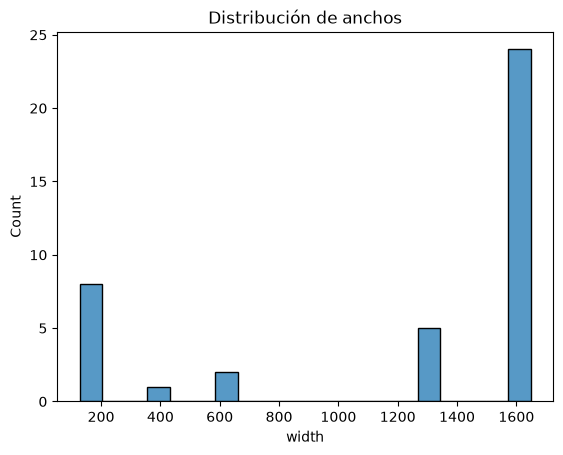

format
PNG    40
Name: count, dtype: int64

In [12]:
if READY:
    display(manifest[["width", "height", "format"]].head())
    sns.histplot(data=manifest, x=pd.to_numeric(manifest["width"], errors="coerce").dropna(), bins=20)
    plt.title("Distribución de anchos")
    plt.show()
    display(manifest["format"].value_counts(dropna=False))

## 9. Galería de imágenes de muestra

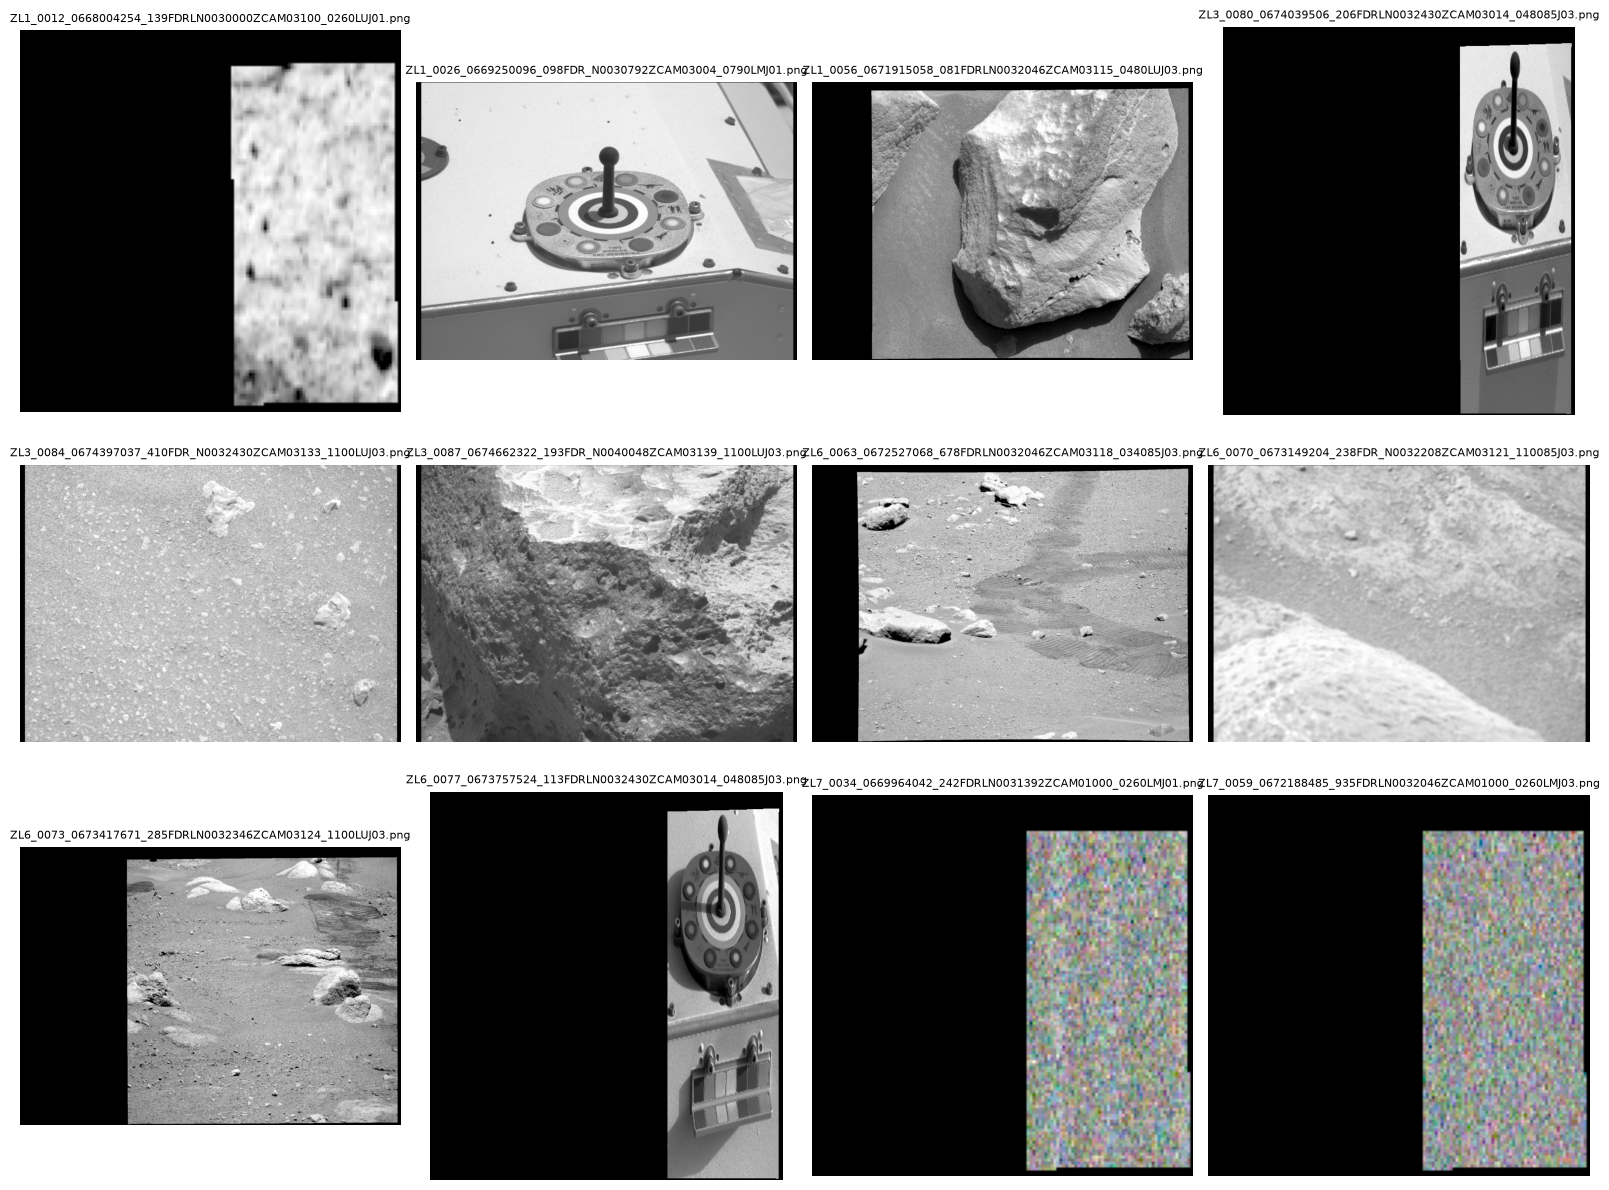

In [13]:
if READY:
    sample_paths = [RAW_DIR / row.relative_path for row in manifest.head(12).itertuples()]
    plot_image_grid(sample_paths)

## 10. Inicialización de DINOv2
Esta es la primera celda que carga pesos externos. Ejecutarla implica que Transformers pueda descargar `facebook/dinov2-small` si no está en caché.

In [15]:
RUN_DINOV2 = True
if READY and RUN_DINOV2:
    embedder = DINOv2Embedder(CONFIG["model"]["name"])
    print(embedder.device)

Loading weights: 100%|█████████████████████████████████████| 223/223 [00:00<00:00, 27258.76it/s]

mps


## 11. Extracción o carga de embeddings

In [16]:
if READY and RUN_DINOV2:
    valid = validation["readable"].to_numpy(dtype=bool)
    valid_manifest = manifest.loc[valid].reset_index(drop=True)
    valid_paths = [RAW_DIR / value for value in valid_manifest["relative_path"]]
    embedding_path = ROOT / CONFIG["paths"]["embeddings"] / "dinov2_embeddings.npz"
    if embedding_path.exists():
        embeddings, embedding_ids = load_embeddings(embedding_path)
        print("Embeddings cargados:", embeddings.shape)
    else:
        embeddings = embedder.embed_images(valid_paths, CONFIG["model"]["batch_size"])
        save_embeddings(embeddings, valid_manifest["image_id"], embedding_path)
        embedding_ids = valid_manifest["image_id"].to_numpy()
        print("Embeddings guardados:", embedding_path, embeddings.shape)

Embeddings guardados: /Users/manuelchoez/Maestria/mars-evidence/outputs/embeddings/dinov2_embeddings.npz (40, 384)


## 12. UMAP

/Users/manuelchoez/Maestria/mars-evidence/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


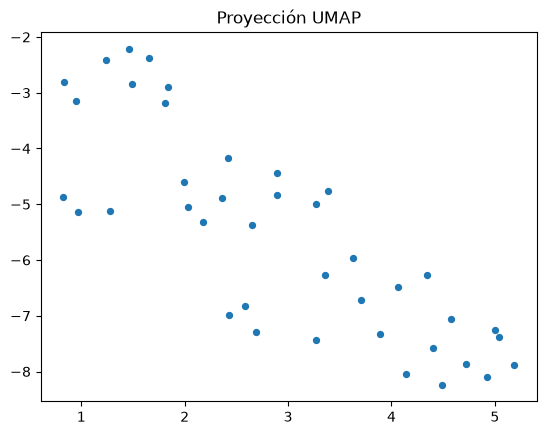

In [17]:
if READY and RUN_DINOV2:
    projection = reduce_umap(embeddings, **CONFIG["umap"], random_state=CONFIG["project"]["seed"])
    plt.scatter(projection[:, 0], projection[:, 1], s=18)
    plt.title("Proyección UMAP")
    plt.show()

## 13. HDBSCAN

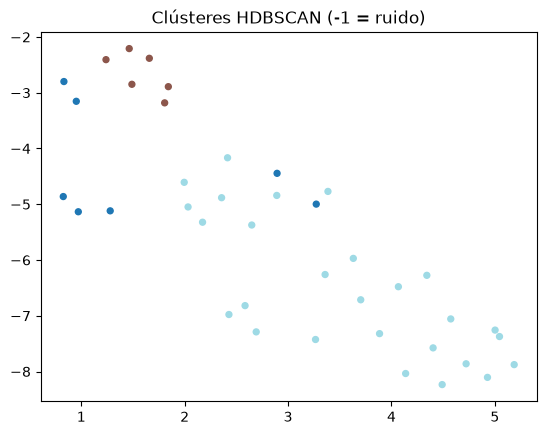

In [18]:
if READY and RUN_DINOV2:
    labels = cluster_hdbscan(embeddings, **CONFIG["hdbscan"])
    plt.scatter(projection[:, 0], projection[:, 1], c=labels, s=18, cmap="tab20")
    plt.title("Clústeres HDBSCAN (-1 = ruido)")
    plt.show()

## 14. Puntuación de anomalía visual
Una distancia coseno media mayor a vecinos cercanos produce mayor `visual_anomaly_score`. Está normalizada entre 0 y 1 y no es una probabilidad científica.

In [19]:
if READY and RUN_DINOV2:
    results = valid_manifest.copy()
    results["visual_anomaly_score"] = visual_anomaly_scores(embeddings, CONFIG["anomaly"]["neighbors"])
    display(results.sort_values("visual_anomaly_score", ascending=False).head(CONFIG["anomaly"]["top_k"]))

,image_id,file_name,relative_path,sha256,width,height,format,file_size_bytes,product_id,sol,earth_date,camera,eye,source_url,metadata_url,stereo_pair_id,processing_level,credit,downloaded_at_utc,visual_anomaly_score
1,ZL1_0026_0669250096_098FDR_N0030792ZCAM03004_0...,ZL1_0026_0669250096_098FDR_N0030792ZCAM03004_0...,ZL1_0026_0669250096_098FDR_N0030792ZCAM03004_0...,f1a14c0cfb37ad1ab87edb80d17f94ae0f71a13e7f0ba3...,1648,1200,PNG,1309962,urn:nasa:pds:mars2020_mastcamz_ops_calibrated:...,26,2021-03-17,Mast Camera Zoom Left,left,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,,Derived,NASA/JPL-Caltech/ASU,2026-09-26T17:41:34.948827Z,1.000000
9,ZL6_0077_0673757524_113FDRLN0032430ZCAM03014_0...,ZL6_0077_0673757524_113FDRLN0032430ZCAM03014_0...,ZL6_0077_0673757524_113FDRLN0032430ZCAM03014_0...,7dad3c6eabb97f9e12ec60ea705fcb3d31aff326d42674...,624,688,PNG,164554,urn:nasa:pds:mars2020_mastcamz_ops_calibrated:...,77,2021-05-08,Mast Camera Zoom Left,left,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,,Derived,NASA/JPL-Caltech/ASU,2026-09-26T18:00:05.435333Z,0.902267
3,ZL3_0080_0674039506_206FDRLN0032430ZCAM03014_0...,ZL3_0080_0674039506_206FDRLN0032430ZCAM03014_0...,ZL3_0080_0674039506_206FDRLN0032430ZCAM03014_0...,acbc12c77e81d5492a483afd064d8a912f3922b3ba4a98...,624,688,PNG,151443,urn:nasa:pds:mars2020_mastcamz_ops_calibrated:...,80,2021-05-11,Mast Camera Zoom Left,left,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,,Derived,NASA/JPL-Caltech/ASU,2026-09-26T18:00:16.620517Z,0.876689
25,ZR2_0089_0674827608_098FDR_N0040048ZCAM01000_0...,ZR2_0089_0674827608_098FDR_N0040048ZCAM01000_0...,ZR2_0089_0674827608_098FDR_N0040048ZCAM01000_0...,e51fc99602e3077f1eeeb78a0014fd6aa62aad69620e27...,1648,1200,PNG,127270,urn:nasa:pds:mars2020_mastcamz_ops_calibrated:...,89,2021-05-21,Mast Camera Zoom Right,right,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,,Derived,NASA/JPL-Caltech/ASU,2026-09-26T18:01:01.838799Z,0.818436
23,ZR2_0082_0674200665_159FDR_N0032430ZCAM01000_0...,ZR2_0082_0674200665_159FDR_N0032430ZCAM01000_0...,ZR2_0082_0674200665_159FDR_N0032430ZCAM01000_0...,9eb72056a2a232036e3e5937370b4b6776d12e66c61400...,1648,1200,PNG,125214,urn:nasa:pds:mars2020_mastcamz_ops_calibrated:...,82,2021-05-13,Mast Camera Zoom Right,right,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,,Derived,NASA/JPL-Caltech/ASU,2026-09-26T18:00:18.713260Z,0.787508
5,ZL3_0087_0674662322_193FDR_N0040048ZCAM03139_1...,ZL3_0087_0674662322_193FDR_N0040048ZCAM03139_1...,ZL3_0087_0674662322_193FDR_N0040048ZCAM03139_1...,0d5797474ea9a6d0d1f7f507f8a830474dcf712ffb2ef3...,1648,1200,PNG,1802449,urn:nasa:pds:mars2020_mastcamz_ops_calibrated:...,87,2021-05-19,Mast Camera Zoom Left,left,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,,Derived,NASA/JPL-Caltech/ASU,2026-09-26T18:01:00.591509Z,0.702210
37,ZRF_0047_0671110922_522FDR_N0031416ZCAM05001_0...,ZRF_0047_0671110922_522FDR_N0031416ZCAM05001_0...,ZRF_0047_0671110922_522FDR_N0031416ZCAM05001_0...,3c915c87d35de3ea3fb97199c31b8c3ff6a5dcd0451389...,1280,720,PNG,827470,urn:nasa:pds:mars2020_mastcamz_ops_calibrated:...,47,2021-04-07,Mast Camera Zoom Right,right,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,,Derived,NASA/JPL-Caltech/ASU,2026-09-26T17:50:53.046117Z,0.701306
16,ZLF_0045_0670943049_238FDRLN0031416ZCAM05014_0...,ZLF_0045_0670943049_238FDRLN0031416ZCAM05014_0...,ZLF_0045_0670943049_238FDRLN0031416ZCAM05014_0...,f579db75746774bef6dcd87719a30428e8b6324ea2cd43...,1648,1200,PNG,4581122,urn:nasa:pds:mars2020_mastcamz_ops_calibrated:...,45,2021-04-06,Mast Camera Zoom Left,left,https://pds-imaging.jpl.nasa.gov/archive/m20/c...,https://pds-imaging.jpl.nasa.gov/archive/m20/

## 15. Galería de las imágenes más inusuales

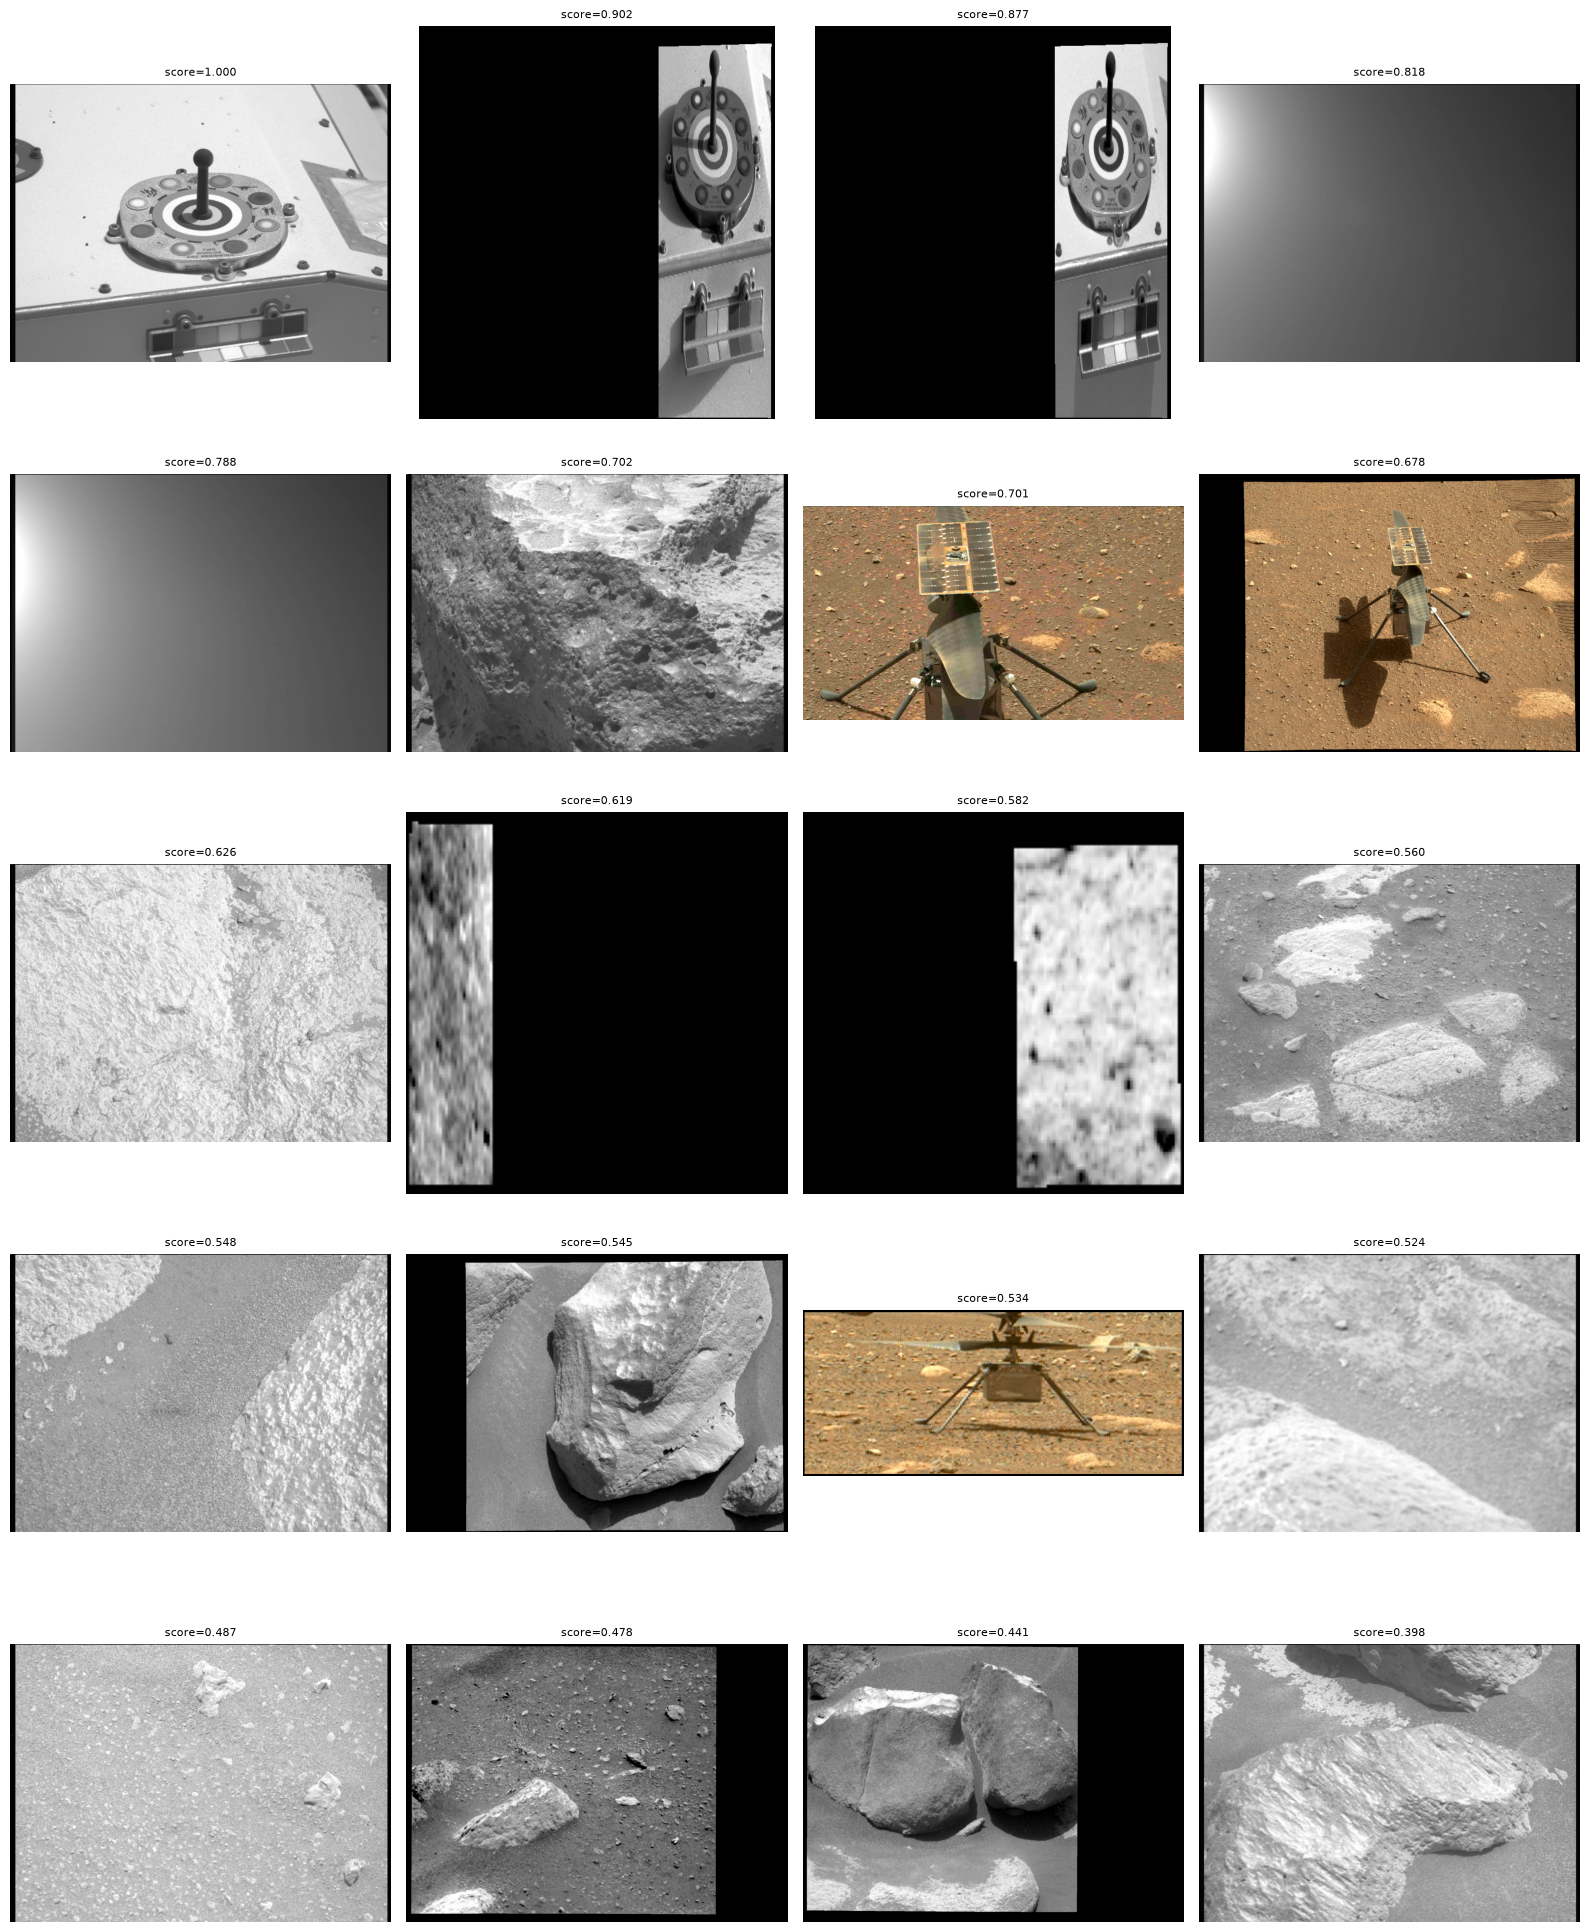

In [20]:
if READY and RUN_DINOV2:
    unusual = results.sort_values("visual_anomaly_score", ascending=False).head(CONFIG["anomaly"]["top_k"])
    plot_image_grid(
        [RAW_DIR / value for value in unusual["relative_path"]],
        [f"score={score:.3f}" for score in unusual["visual_anomaly_score"]],
    )

## 16. Búsqueda de imágenes similares

,image_id,relative_path,similarity_score
0,ZR3_0051_0671470542_098FDRLN0031950ZCAM03111_0...,ZR3_0051_0671470542_098FDRLN0031950ZCAM03111_0...,0.650692
1,ZL7_0059_0672188485_935FDRLN0032046ZCAM01000_0...,ZL7_0059_0672188485_935FDRLN0032046ZCAM01000_0...,0.528531
2,ZR7_0029_0669509674_978FDRLN0030792ZCAM01000_0...,ZR7_0029_0669509674_978FDRLN0030792ZCAM01000_0...,0.518954
3,ZR7_0068_0672993699_108FDRLN0032208ZCAM01505_0...,ZR7_0068_0672993699_108FDRLN0032208ZCAM01505_0...,0.498598
4,ZR2_0075_0673604045_456FDR_N0032430ZCAM03125_0...,ZR2_0075_0673604045_456FDR_N0032430ZCAM03125_0...,0.451759


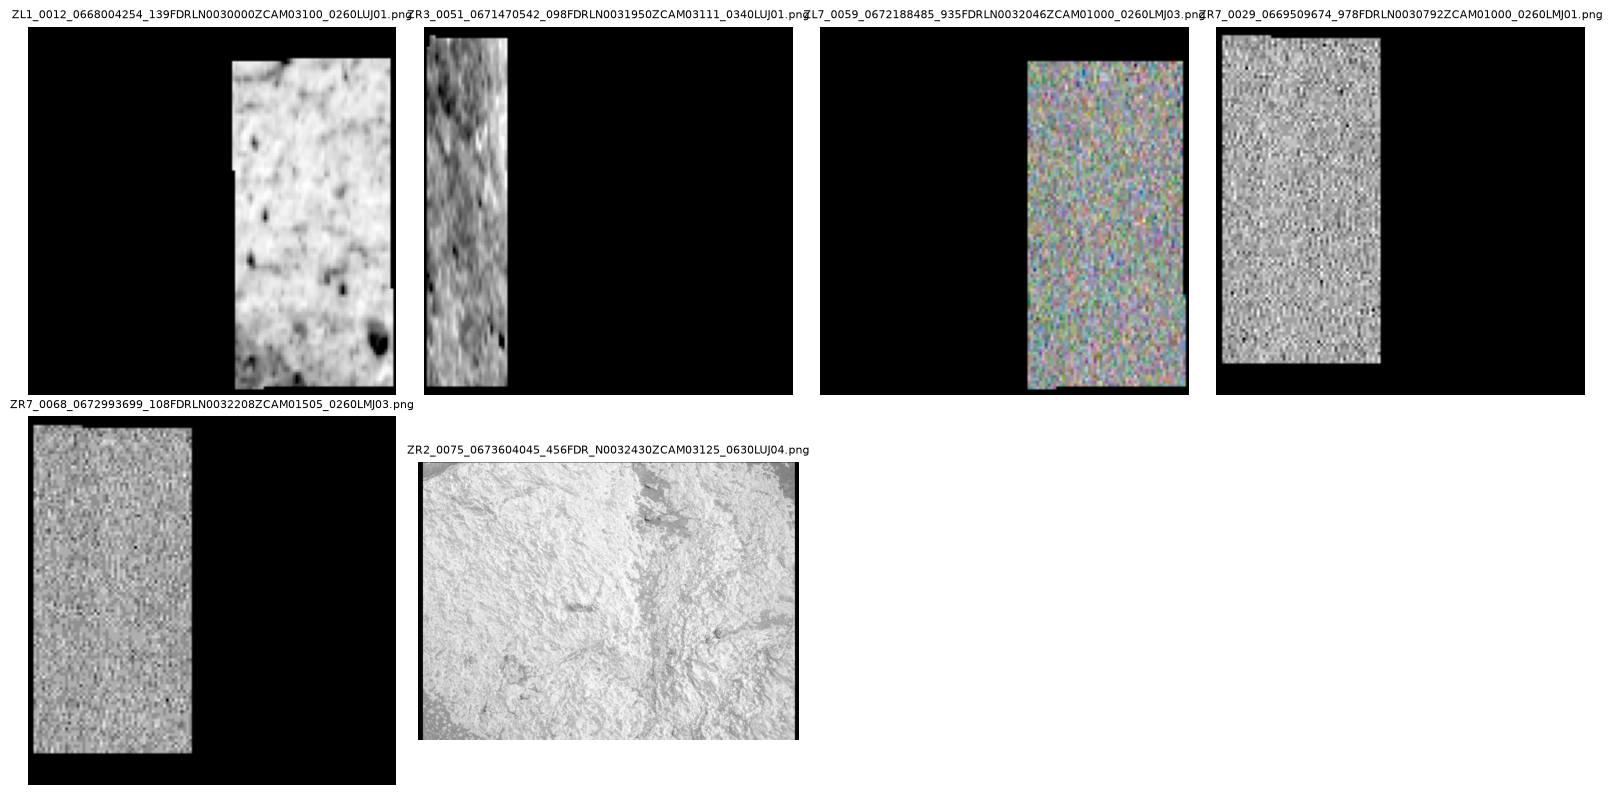

In [21]:
if READY and RUN_DINOV2:
    query_index = 0
    similar = find_similar(embeddings, valid_manifest, query_index, k=5)
    display(similar[["image_id", "relative_path", "similarity_score"]])
    plot_image_grid(
        [RAW_DIR / valid_manifest.iloc[query_index]["relative_path"]]
        + [RAW_DIR / value for value in similar["relative_path"]]
    )

## 17. Limitaciones
El resultado depende de la calidad, procedencia, iluminación, compresión y diversidad del conjunto. DINOv2 no fue entrenado como instrumento científico marciano; UMAP distorsiona distancias para visualización; HDBSCAN y k vecinos dependen de sus parámetros; y los duplicados o familias de imágenes pueden sesgar la rareza.

## 18. Próximos pasos
Añadir metadatos oficiales con fuentes verificables, evaluar sensibilidad de parámetros, incorporar revisión humana y documentar procedencia. Como fases posteriores quedan PatchCore, visión estéreo y análisis químico; no se implementan en esta iteración.